# Prepaid Card Marketing — Mini-Project 2
## Part 4 of 5: Card company marketing and origination strategy (Task C)

**Question.** Can a card company build a marketing and origination strategy around who to target for a prepaid card, and what are the key insights about who is likely to use one?

**Purpose.** Turn the chosen model from Part 3 into a practical, responsible strategy: who is most likely to use a reloadable prepaid card, which of those signals a company can actually see, and how the product should be marketed and originated.

| Section | What it delivers |
|---|---|
| 1. Setup | The shared split, the 20 predictors and the chosen model's scores |
| 2. What drives the score | The model's weights, read as odds ratios |
| 3. Target segments | Size, usage rate and lift of each candidate segment, confirmed on the test set |
| 4. Reachability | How much targeting power survives when only company-observable data is used |
| 5. Strategy | Who to target, channels, message, origination and measurement, each tied to evidence |
| 6. Responsible marketing | Who the targeting rule reaches, by race/ethnicity |
| 7. Conclusions and limitations | What the company can and cannot rely on |

### Summary

- **Target the top 20% of model scores.** On the test set the rule flags 246 of 1,274 people (19.3%), reaches 62 of the 112 prepaid users (55.4%), and 25.2% of those flagged are users: **2.87 times** the 8.8% average. On the larger training set the figures are 48.9% of users and 2.44 times. Plan on **about half of users at roughly 2.4 to 2.9 times the average rate**. Three in four people flagged are not users.
- **What raises the score most is access to mainstream finance and credit distress.** Having a bank account has the largest weight (odds ratio 0.58). Contact from a debt collector (1.44), SNAP benefits (1.37), being turned down for credit (1.32), financial shocks (1.29 per standard deviation) and renting (1.62 against owning) raise it. Higher financial knowledge lowers it (0.80 per standard deviation).
- **Savings, ability to raise \$2,000, well-being and the hardship count add almost nothing inside the model**, although each is strongly related to prepaid use on its own. Other predictors already carry their signal: removing the three liquidity measures leaves the training lift at 2.43 (from 2.44).
- **A company can get most of this from data it can observe.** With the 12 predictors a company can observe or partly observe, the top-20% lift is 2.39 on training data (98% of the full model) and 2.47 on test data (86%). With only the 4 it clearly has (income, age, housing, debt-collection contact), lift is 2.24 and 2.23 (92% and 78%).
- **"The unbanked" is not the market.** 69.2% of prepaid users have a bank account. The top-20% rule mostly finds the financially fragile users; the half of users it misses are 89.1% banked and need a different, mainstream message.
- **The best prospects are also the most fee-sensitive.** Among those flagged, 71.1% report a material hardship and 59.2% have under \$1,000 in savings. The rule also flags 43.8% of Black and 38.5% of Hispanic respondents against 12.9% of White respondents, though race is not a predictor. Transparent, low-fee product design is part of the strategy, not an afterthought.

All results are associations in a 2016 self-reported survey, unweighted as the brief requires. They are not causal effects, national estimates or forecasts of revenue.

---
# 1. Setup

This notebook uses the fixed train/test split and 20 predictors from Part 2, and the chosen model and its scores from Part 3. Nothing is re-split, re-cleaned or re-tuned.

- **Training scores are out-of-fold:** each of the 5,093 training respondents was scored by a model that did not see them, so they can be used for profiling without leakage.
- **Test scores** (1,274 respondents) are used only to confirm the patterns found on the training scores.
- **The top-20% rule** from Part 3 is applied as a fixed score cut-off taken from the training scores.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

import prep
from prep import build_preprocessor, feature_lists, feature_table, load_profile, load_split, readable_names

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60, "display.width", 220, "display.max_colwidth", 110, "display.max_rows", 100)

DATA_DIR = Path("data")
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)
SEED = 42
TOP_SHARE = 0.20

INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
BLUE, ORANGE = "#2a78d6", "#eb6834"
mpl.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 10, "text.color": INK, "axes.labelcolor": INK2,
    "axes.titlesize": 11.5, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 10,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.7,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "xtick.labelsize": 9, "ytick.labelsize": 9, "legend.frameon": False, "legend.fontsize": 9,
})


def fmt(df, formats, hide_index=False):
    """Return a display copy of a table with numbers formatted as text."""
    out = df.copy()
    if isinstance(formats, str):
        formats = {c: formats for c in out.columns if pd.api.types.is_numeric_dtype(out[c])}
    for col, pattern in formats.items():
        if col in out.columns:
            out[col] = out[col].map(lambda v, p=pattern: p.format(v) if pd.notna(v) else "")
    return out.reset_index(drop=True) if hide_index else out


def logit():
    """The chosen model's settings from Part 3."""
    return LogisticRegression(C=10, class_weight="balanced", max_iter=5000, random_state=SEED)


X_train, X_test, y_train, y_test = load_split()
train_scores = pd.read_csv(DATA_DIR / "train_oof_scores.csv", index_col="PUF_ID")
test_scores = pd.read_csv(DATA_DIR / "test_scores.csv", index_col="PUF_ID")
train_raw = pd.read_csv(DATA_DIR / "train.csv", index_col="PUF_ID")
test_raw = pd.read_csv(DATA_DIR / "test.csv", index_col="PUF_ID")
features = feature_table()

assert train_scores.index.equals(train_raw.index) and test_scores.index.equals(test_raw.index)
assert train_scores["score_chosen"].notna().all() and test_scores["score_chosen"].notna().all()
base_rate = y_train.mean()
threshold = float(np.quantile(train_scores["score_chosen"], 1 - TOP_SHARE))
print(f"Training: {len(train_raw):,} respondents, {int(y_train.sum())} prepaid users ({base_rate:.1%})")
print(f"Test:     {len(test_raw):,} respondents, {int(y_test.sum())} prepaid users ({y_test.mean():.1%})")
print(f"Top-{TOP_SHARE:.0%} rule from Part 3: score_chosen >= {threshold:.3f} (cut-off fixed on training scores)")

# Refit the chosen model from its documented settings, so this notebook does not depend on a saved model file.
chosen_model = Pipeline([("prep", build_preprocessor()), ("model", logit())]).fit(X_train, y_train)
refit_test_scores = chosen_model.predict_proba(X_test)[:, 1]
assert np.allclose(refit_test_scores, test_scores["score_chosen"].to_numpy(), atol=1e-8)
print("Refitted chosen model reproduces the Part 3 test scores exactly.")

Training: 5,093 respondents, 448 prepaid users (8.8%)
Test:     1,274 respondents, 112 prepaid users (8.8%)
Top-20% rule from Part 3: score_chosen >= 0.600 (cut-off fixed on training scores)
Refitted chosen model reproduces the Part 3 test scores exactly.


---
# 2. What drives the score?

The chosen model is a logistic regression: it adds up one weight per predictor and turns the total into a score. A positive weight raises the score, a negative weight lowers it, **holding the other 19 predictors fixed**.

**Odds ratio** = `exp(weight)`. An odds ratio of 1.44 means the odds of being a prepaid user are 44% higher; 0.58 means 42% lower. For yes/no predictors it compares yes with no. For ordered scales and scores, which were standardised, it is the change for a one-standard-deviation increase.

**Two cautions before reading the tables**

1. **Weights are not the same as the raw patterns in Part 1.** Part 1 looked at one variable at a time. A model weight is what a predictor adds *after* the other 19 are accounted for. A variable that is strongly related to prepaid use on its own can have a small weight if other predictors already carry its signal.
2. **These are associations, not causes.**

The saved model keeps every category of housing, employment and marital status, so those weights have no reference group. The second table refits the same model with a reference category (owns home, self-employed, married) to give odds ratios that can be read as "compared with".

In [2]:
full_coef = pd.Series(chosen_model.named_steps["model"].coef_[0], index=readable_names(chosen_model.named_steps["prep"]), name="Weight")
raw_names = pd.Series(chosen_model.named_steps["prep"].get_feature_names_out(), index=full_coef.index)

scaled_cols, binary_cols, nominal_cols = feature_lists()
single = full_coef[[features.loc[c, "label"] for c in scaled_cols + binary_cols]].to_frame()
single["Odds ratio"] = np.exp(single["Weight"])
single["Type"] = ["Per 1 standard deviation"] * len(scaled_cols) + ["Yes vs no"] * len(binary_cols)
single["Rank by size (of 33 model columns)"] = full_coef.abs().rank(ascending=False).astype(int)[single.index]
single = single.sort_values("Weight", key=np.abs, ascending=False)
print("Yes/no predictors and ordered scales (17 of the 20 predictors), largest weight first:")
display(fmt(single, {"Weight": "{:+.3f}", "Odds ratio": "{:.2f}"}))

Yes/no predictors and ordered scales (17 of the 20 predictors), largest weight first:


,Weight,Odds ratio,Type,Rank by size (of 33 model columns)
Has: Checking or Savings Account at a bank or credit union,-0.546,0.58,Yes vs no,1
Contacted by debt collector in past 12 months,+0.368,1.44,Yes vs no,2
Any household member received SNAP benefits,+0.311,1.37,Yes vs no,5
I applied for credit and was turned down,+0.279,1.32,Yes vs no,6
Number of financial shocks in the past year (0-11),+0.253,1.29,Per 1 standard deviation,7
Knoll and Houts financial knowledge scale score,-0.226,0.80,Per 1 standard deviation,12
Household Income,-0.162,0.85,Per 1 standard deviation,16
Has: Retirement Account (such as a 401k or IRA),-0.154,0.86,Yes vs no,17
Age,+0.142,1.15,Per 1 standard deviation,18
Household income volatility,+0.121,1.13,Per 1 standard deviation,20


In [3]:
# Category predictors: refit with a reference category so each odds ratio reads as "compared with the reference".
reference_model = Pipeline([("prep", build_preprocessor(drop_first=True)), ("model", logit())]).fit(X_train, y_train)
rank_agreement = pd.Series(reference_model.predict_proba(X_test)[:, 1]).corr(pd.Series(refit_test_scores), method="spearman")
assert rank_agreement > 0.999, "The reference-category refit must rank people the same way as the chosen model"

ref_coef = pd.Series(reference_model.named_steps["model"].coef_[0], index=readable_names(reference_model.named_steps["prep"]))
SHORT = {"Which one of the following best describes your housing situation?": "Housing",
         "Primary or only employment status": "Employment", "Marital Status": "Marital status"}
category = ref_coef[[i for i in ref_coef.index if i.split(": ")[0] in SHORT]].rename("Weight").to_frame()
category["Odds ratio vs reference"] = np.exp(category["Weight"])
category.index = [SHORT[i.split(": ")[0]] + ": " + i.split(": ")[1] for i in category.index]
category["Reference group"] = [{"Housing": "Owns home", "Employment": "Self-employed", "Marital status": "Married"}[i.split(":")[0]] for i in category.index]
category = category.sort_values("Weight", key=np.abs, ascending=False)
print(f"Scores from this refit rank test respondents identically to the chosen model (rank correlation {rank_agreement:.3f}).")
display(fmt(category, {"Weight": "{:+.3f}", "Odds ratio vs reference": "{:.2f}"}))

group_sizes = pd.DataFrame({"Widowed": [(train_raw["PPMARIT"] == 2).sum(), train_raw.loc[train_raw["PPMARIT"] == 2, "PRODUSE_3"].sum()],
                            "Homemaker": [(train_raw["EMPLOY"] == 4).sum(), train_raw.loc[train_raw["EMPLOY"] == 4, "PRODUSE_3"].sum()],
                            "Full-time student": [(train_raw["EMPLOY"] == 5).sum(), train_raw.loc[train_raw["EMPLOY"] == 5, "PRODUSE_3"].sum()]},
                           index=["Training respondents", "of whom prepaid users"]).astype(int)
print("Size of the three category groups with the largest weights:")
display(group_sizes)

Scores from this refit rank test respondents identically to the chosen model (rank correlation 1.000).


,Weight,Odds ratio vs reference,Reference group
Housing: Rents,+0.485,1.62,Owns home
Housing: Neither owns nor rents,+0.460,1.58,Owns home
Marital status: Widowed,+0.456,1.58,Married
Employment: Homemaker,-0.428,0.65,Self-employed
Employment: Full-time student,-0.359,0.70,Self-employed
Marital status: Never married,+0.195,1.22,Married
Marital status: Divorced / separated,+0.168,1.18,Married
Marital status: Living with partner,-0.154,0.86,Married
"Employment: Sick, disabled or unable to work",+0.119,1.13,Self-employed
Employment: Works full-time,-0.103,0.90,Self-employed


Size of the three category groups with the largest weights:


,Widowed,Homemaker,Full-time student
Training respondents,293,285,179
of whom prepaid users,36,23,14


### The liquidity group, and hardship, carry little weight inside the model

Part 1 found savings, the ability to raise \$2,000 and financial well-being among the variables most strongly related to prepaid use when looked at one at a time. The table above shows that **inside the model they barely matter**. The next cell measures this directly by removing them and re-scoring.

In [4]:
liquidity = ["SAVINGSRANGES", "ABSORBSHOCK", "FWBscore"]
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)


def subset_preprocessor(columns):
    """The shared preparation rules from prep.py, applied to a subset of the 20 predictors."""
    columns = list(columns)
    return ColumnTransformer([
        ("scaled", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), [c for c in scaled_cols if c in columns]),
        ("binary", SimpleImputer(strategy="most_frequent"), [c for c in binary_cols if c in columns]),
        ("nominal", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                              ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), [c for c in nominal_cols if c in columns]),
    ], remainder="drop", verbose_feature_names_out=False)


def targeting_metrics(y, flag):
    y, flag = np.asarray(y), np.asarray(flag)
    hits = int((flag & (y == 1)).sum())
    return {"People flagged": int(flag.sum()), "Share flagged": flag.mean(), "Usage rate among flagged": y[flag].mean(),
            "Recall (share of users caught)": hits / int((y == 1).sum()), "Lift": y[flag].mean() / y.mean()}


def subset_scores(columns):
    """Out-of-fold training scores and test scores for the chosen model fitted on a subset of predictors."""
    model = Pipeline([("prep", subset_preprocessor(columns)), ("model", logit())])
    oof = cross_val_predict(model, X_train[columns], y_train, cv=folds, method="predict_proba")[:, 1]
    test = model.fit(X_train[columns], y_train).predict_proba(X_test[columns])[:, 1]
    return oof, test


def top20_rows(label, oof, test):
    """Top-20% results, with the cut-off fixed on the training scores and applied unchanged to the test set."""
    cutoff = np.quantile(oof, 1 - TOP_SHARE)
    return [{"Predictors used": label, "File": "Training (out-of-fold)", **targeting_metrics(y_train, oof >= cutoff)},
            {"Predictors used": label, "File": "Test", **targeting_metrics(y_test, test >= cutoff)}]


without_liquidity = [c for c in features.index if c not in liquidity]
oof_wo, test_wo = subset_scores(without_liquidity)
ablation = pd.DataFrame(top20_rows("All 20 predictors", train_scores["score_chosen"].to_numpy(), test_scores["score_chosen"].to_numpy())
                        + top20_rows("17 predictors (savings, raise $2,000 and well-being removed)", oof_wo, test_wo))
display(fmt(ablation, {"Share flagged": "{:.1%}", "Usage rate among flagged": "{:.1%}", "Recall (share of users caught)": "{:.1%}", "Lift": "{:.2f}x"}))
rho = pd.Series(test_wo).corr(pd.Series(test_scores["score_chosen"].to_numpy()), method="spearman")
print(f"Rank correlation between test scores with and without the three liquidity predictors: {rho:.3f}")

,Predictors used,File,People flagged,Share flagged,Usage rate among flagged,Recall (share of users caught),Lift
0,All 20 predictors,Training (out-of-fold),1019,20.0%,21.5%,48.9%,2.44x
1,All 20 predictors,Test,246,19.3%,25.2%,55.4%,2.87x
2,"17 predictors (savings, raise $2,000 and well-being removed)",Training (out-of-fold),1019,20.0%,21.4%,48.7%,2.43x
3,"17 predictors (savings, raise $2,000 and well-being removed)",Test,242,19.0%,24.4%,52.7%,2.77x


Rank correlation between test scores with and without the three liquidity predictors: 0.997


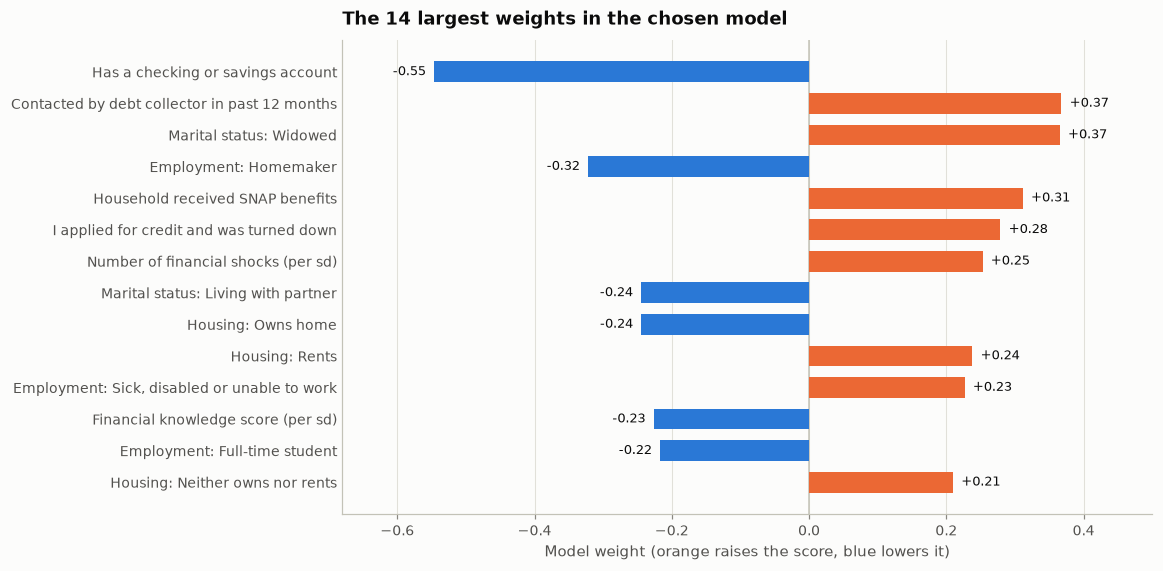

In [5]:
top = full_coef.reindex(full_coef.abs().sort_values(ascending=False).index).head(14).iloc[::-1]
labels = [l.replace("Which one of the following best describes your housing situation?", "Housing")
           .replace("Primary or only employment status", "Employment").replace("Marital Status", "Marital status")
           .replace("Has: Checking or Savings Account at a bank or credit union", "Has a checking or savings account")
           .replace("Any household member received SNAP benefits", "Household received SNAP benefits")
           .replace("Knoll and Houts financial knowledge scale score", "Financial knowledge score (per sd)")
           .replace("Number of financial shocks in the past year (0-11)", "Number of financial shocks (per sd)")
           .replace("Household Income", "Household income (per sd)") for l in top.index]
fig, ax = plt.subplots(figsize=(9.5, 5.6))
ax.barh(np.arange(len(top)), top.values, height=0.66, color=[ORANGE if v > 0 else BLUE for v in top.values], zorder=3)
for i, v in enumerate(top.values):
    ax.text(v + (0.012 if v > 0 else -0.012), i, f"{v:+.2f}", va="center", ha="left" if v > 0 else "right", fontsize=8.5, color=INK)
ax.axvline(0, color=AXIS, linewidth=1)
ax.set_yticks(np.arange(len(top)), labels)
ax.set_xlim(-0.68, 0.50)
ax.set_xlabel("Model weight (orange raises the score, blue lowers it)")
ax.set_title("The 14 largest weights in the chosen model")
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0)
fig.savefig(FIG_DIR / "19_score_associations.png")
plt.show()

**Takeaways**

- **Bank-account status has the largest weight.** People with a checking or savings account have 42% lower odds of prepaid use (odds ratio 0.58), with everything else held fixed.
- **Credit distress and benefit receipt raise the score:** contacted by a debt collector (odds ratio 1.44), household on SNAP (1.37), turned down for credit (1.32), and each standard deviation more financial shocks (1.29).
- **Housing matters:** renters have 1.62 times, and people who neither own nor rent 1.58 times, the odds of homeowners.
- **Knowledge and income lower the score:** 0.80 and 0.85 per standard deviation.
- **Liquidity and hardship carry almost no weight inside the model.** Savings (0.95), ability to raise \$2,000 (1.03), financial well-being (1.07) and the hardship count (1.05) rank 26th to 30th of the 33 model columns, and two of the three liquidity weights point the "wrong" way, which is what weights near zero do. Removing all three liquidity predictors leaves the top-20% lift at 2.43 on training data (from 2.44) and 2.77 on test data (from 2.87), and the two sets of scores rank people almost identically (rank correlation 0.997).
  - **This does not contradict Part 1.** Low savings and hardship are strongly related to prepaid use on their own. The model shows that bank-account status, SNAP, debt collection, credit rejection and shocks already carry that signal.
  - **It is good news for the company,** because savings, well-being and hardship are survey-only and cannot be observed for a prospect anyway.
- **Age has a small positive weight (1.15 per standard deviation), the opposite of the raw pattern** in Part 1, where younger adults use prepaid cards more. Once renting, income and employment are held fixed, the age gap is explained away. It is not a reason to target older people.
- **Education and health insurance have weights close to zero** once the other predictors are known.
- **Treat the category weights with care.** Widowed (1.58 against married), homemaker (0.65) and full-time student (0.70, both against self-employed) are large, but rest on 36, 23 and 14 prepaid users. They are tentative.

---
# 3. Target segments and confirmation on the test set

Each segment is defined by one plain rule a marketing team could act on. For each one the table gives:

- **People** and **share of file:** how big the segment is.
- **Usage rate:** the share of the segment who reported using a prepaid card.
- **Lift:** that rate divided by the overall rate in the same file (8.8%). A lift of 2.0x means twice the average.

Segments are defined on the training set and confirmed on the test set. They overlap heavily (the same person can be a renter, on SNAP and without a bank account), so their sizes must not be added together.

In [6]:
KNOWLEDGE_CUT = float(X_train["KHscore"].quantile(0.25))      # fixed on the training set, applied unchanged to the test set
knowledge_share = (X_train["KHscore"] <= KNOWLEDGE_CUT).mean()


def segment_masks(df):
    return {
        "Top 20% of model scores": df["score_chosen"] >= threshold,
        "Household received SNAP benefits": df["SNAP"] == 1,
        "Turned down for credit": df["REJECTED_1"] == 1,
        "No checking or savings account reported": df["PRODHAVE_1"] == 0,
        "Savings under $1,000": df["SAVINGSRANGES"] <= 3,
        "At least one material hardship": df["HARDSHIP_COUNT"] >= 1,
        "Disabled, unemployed or working part-time": df["EMPLOY"].isin([3, 6, 7]),
        "Rents, or neither owns nor rents": df["HOUSING"].isin([2, 3]),
        f"Low financial knowledge (lowest {knowledge_share:.0%} of scores)": df["KHscore"] <= KNOWLEDGE_CUT,
    }


def segment_table(raw, scores):
    df = raw.join(scores[["score_chosen"]], how="inner")
    overall = df["PRODUSE_3"].mean()
    rows = []
    for segment, mask in segment_masks(df).items():
        rate = df.loc[mask, "PRODUSE_3"].mean()
        rows.append({"Segment": segment, "People": int(mask.sum()), "Share of file": mask.mean(),
                     "Users": int(df.loc[mask, "PRODUSE_3"].sum()), "Usage rate": rate, "Lift": rate / overall})
    return pd.DataFrame(rows).set_index("Segment")


train_segments, test_segments = segment_table(train_raw, train_scores), segment_table(test_raw, test_scores)
segment_results = train_segments.add_suffix(" (train)").join(test_segments.add_suffix(" (test)"))
display(fmt(segment_results, {"People (train)": "{:,}", "Share of file (train)": "{:.1%}", "Usage rate (train)": "{:.1%}", "Lift (train)": "{:.2f}x",
                              "Share of file (test)": "{:.1%}", "Usage rate (test)": "{:.1%}", "Lift (test)": "{:.2f}x"}))
print(f"Overall usage rate: {y_train.mean():.1%} in training, {y_test.mean():.1%} in test.")
print(f"Low financial knowledge = KHscore at or below {KNOWLEDGE_CUT} (the training 25th percentile). "
      f"The score takes only 11 values, so this covers {knowledge_share:.1%} of people, not 25%.")

,People (train),Share of file (train),Users (train),Usage rate (train),Lift (train),People (test),Share of file (test),Users (test),Usage rate (test),Lift (test)
Segment,,,,,,,,,,
Top 20% of model scores,"1,019",20.0%,219,21.5%,2.44x,246,19.3%,62,25.2%,2.87x
Household received SNAP benefits,491,9.6%,113,23.0%,2.62x,123,9.7%,21,17.1%,1.94x
Turned down for credit,504,9.9%,98,19.4%,2.21x,137,10.8%,24,17.5%,1.99x
No checking or savings account reported,715,14.0%,138,19.3%,2.19x,207,16.2%,43,20.8%,2.36x
"Savings under $1,000","1,212",23.8%,202,16.7%,1.89x,294,23.1%,42,14.3%,1.62x
At least one material hardship,"1,458",28.6%,236,16.2%,1.84x,371,29.1%,57,15.4%,1.75x
"Disabled, unemployed or working part-time",746,14.6%,119,16.0%,1.81x,200,15.7%,30,15.0%,1.71x
"Rents, or neither owns nor rents","1,754",34.4%,263,15.0%,1.70x,426,33.4%,56,13.1%,1.50x
Low financial knowledge (lowest 35% of scores),"1,772",34.8%,252,14.2%,1.62x,440,34.5%,77,17.5%,1.99x


Overall usage rate: 8.8% in training, 8.8% in test.
Low financial knowledge = KHscore at or below -0.57 (the training 25th percentile). The score takes only 11 values, so this covers 34.8% of people, not 25%.


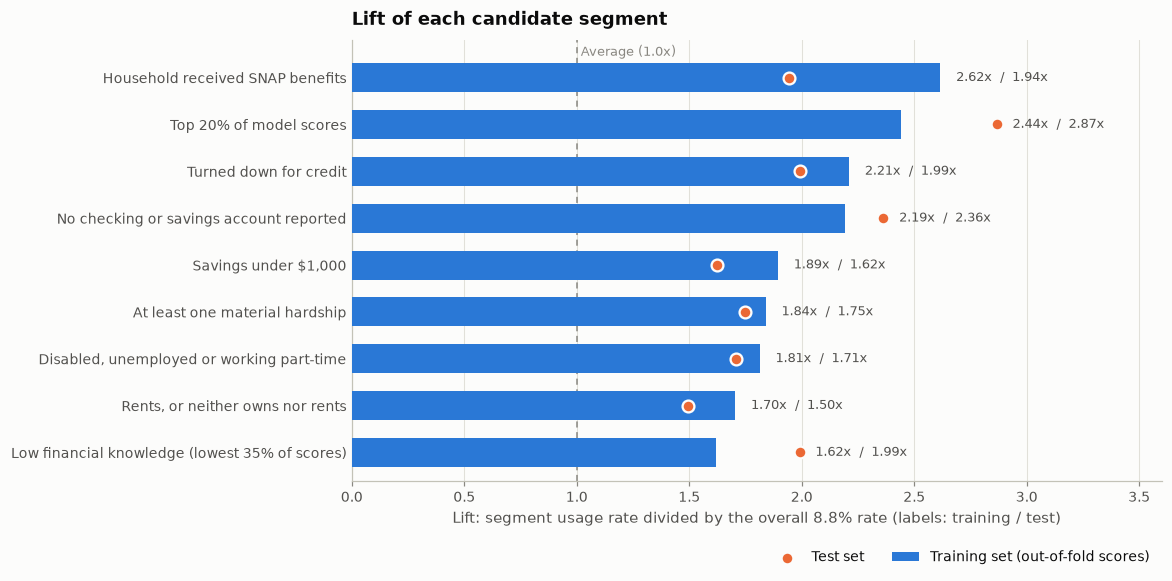

In [7]:
order = train_segments.sort_values("Lift").index
y_pos = np.arange(len(order))
fig, ax = plt.subplots(figsize=(9.5, 5.2))
ax.barh(y_pos, train_segments.loc[order, "Lift"], height=0.62, color=BLUE, zorder=3, label="Training set (out-of-fold scores)")
ax.scatter(test_segments.loc[order, "Lift"], y_pos, s=60, color=ORANGE, edgecolor=SURFACE, linewidth=1.5, zorder=4, label="Test set")
for i, seg in enumerate(order):
    right = max(train_segments.loc[seg, "Lift"], test_segments.loc[seg, "Lift"])
    ax.text(right + 0.07, i, f"{train_segments.loc[seg, 'Lift']:.2f}x  /  {test_segments.loc[seg, 'Lift']:.2f}x", va="center", fontsize=8.5, color=INK2)
ax.axvline(1, color=MUTED, linewidth=1, linestyle=(0, (4, 3)))
ax.text(1.0, len(order) - 0.45, " Average (1.0x)", fontsize=8.5, color=MUTED, va="center")
ax.set_yticks(y_pos, order)
ax.set_xlim(0, 3.6)
ax.set_ylim(-0.6, len(order) - 0.2)
ax.set_xlabel("Lift: segment usage rate divided by the overall 8.8% rate (labels: training / test)")
ax.set_title("Lift of each candidate segment")
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0)
ax.legend(loc="upper right", bbox_to_anchor=(1.0, -0.13), ncol=2)
fig.savefig(FIG_DIR / "20_target_segments.png")
plt.show()

In [8]:
def score_deciles(y, score):
    out = pd.DataFrame({"y": np.asarray(y), "score": np.asarray(score)}).sort_values("score", ascending=False).reset_index(drop=True)
    out["Score decile (1 = highest)"] = np.arange(len(out)) * 10 // len(out) + 1
    t = out.groupby("Score decile (1 = highest)").agg(People=("y", "size"), Users=("y", "sum"), Usage_rate=("y", "mean"))
    t["Cumulative share of users"] = t["Users"].cumsum() / out["y"].sum()
    return t


deciles = score_deciles(y_train, train_scores["score_chosen"]).add_suffix(" (train)").join(
    score_deciles(y_test, test_scores["score_chosen"]).add_suffix(" (test)"))
display(fmt(deciles, {"Usage_rate (train)": "{:.1%}", "Cumulative share of users (train)": "{:.1%}",
                      "Usage_rate (test)": "{:.1%}", "Cumulative share of users (test)": "{:.1%}"}))

users = train_raw[train_raw["PRODUSE_3"] == 1]
flagged_users = train_raw[(train_scores["score_chosen"] >= threshold) & (train_raw["PRODUSE_3"] == 1)]
print(f"Of the {len(users)} prepaid users in the training set, {users['PRODHAVE_1'].mean():.1%} have a checking or savings account "
      f"and {(users['PPINCIMP'] >= 3).mean():.1%} have household income of $30,000 or more.")
missed_users = train_raw[(train_scores["score_chosen"] < threshold) & (train_raw["PRODUSE_3"] == 1)]
print(f"Of the {len(flagged_users)} users inside the top 20% of scores, {flagged_users['PRODHAVE_1'].mean():.1%} have an account.")
print(f"Of the {len(missed_users)} users outside the top 20%, {missed_users['PRODHAVE_1'].mean():.1%} have an account.")

,People (train),Users (train),Usage_rate (train),Cumulative share of users (train),People (test),Users (test),Usage_rate (test),Cumulative share of users (test)
Score decile (1 = highest),,,,,,,,
1,510,131,25.7%,29.2%,128,32,25.0%,28.6%
2,509,88,17.3%,48.9%,127,30,23.6%,55.4%
3,509,59,11.6%,62.1%,128,9,7.0%,63.4%
4,510,46,9.0%,72.3%,127,9,7.1%,71.4%
5,509,24,4.7%,77.7%,127,7,5.5%,77.7%
6,509,34,6.7%,85.3%,128,5,3.9%,82.1%
7,510,16,3.1%,88.8%,127,11,8.7%,92.0%
8,509,17,3.3%,92.6%,128,3,2.3%,94.6%
9,509,20,3.9%,97.1%,127,6,4.7%,100.0%


Of the 448 prepaid users in the training set, 69.2% have a checking or savings account and 61.4% have household income of $30,000 or more.
Of the 219 users inside the top 20% of scores, 48.4% have an account.
Of the 229 users outside the top 20%, 89.1% have an account.


**Takeaways**

- **The model score is the best single way to target.** The top 20% of scores has a usage rate of 21.5% on training data (2.44 times the average) and 25.2% on the test set (2.87 times). The top two score deciles hold 48.9% of all users in training and 55.4% in the test set. Below the top 20% the advantage fades quickly: the third decile is at 11.6% in training and 7.0% in the test set, and every lower decile is at or within a fraction of a point of the 8.8% average, or below it.
- **Every single-rule segment beats the average,** by 1.6 to 2.6 times in training and 1.5 to 2.4 times in the test set.
- **Small segments are unstable.** SNAP households have the highest lift in training (23.0%, 2.62 times) but 17.1% (1.94 times) among the 123 in the test set. "No bank account reported" is the most consistent: 19.3% and 20.8%.
- **Size trades off against lift.** The largest segment, people who rent or neither own nor rent (34% of everyone), has the weakest training lift after low knowledge (1.70 times).
- **Most users are not in these segments at all.** 69.2% of prepaid users have a bank account and 61.4% have household income of \$30,000 or more. Inside the top 20% only 48.4% of users have an account; the 229 users the rule misses are 89.1% banked. The rule is good at finding fragile users and poor at finding mainstream ones.

---
# 4. Reachability: what can a card company actually observe?

The model uses survey answers. A card company cannot ask a prospect how many hardships they faced last year. Part 2 marked each predictor by how realistically a company could know it about a prospect (the team's judgement, recorded in `data/selected_features.csv`):

- **Yes:** routinely available, such as stated income, age, home ownership, and debt-collection activity from a credit bureau.
- **Partly:** available in some settings, such as on an application form or from a partner (bank-account status, employment, credit rejections, payment history).
- **Survey only:** not observable (savings, hardship, SNAP, financial knowledge, well-being, shocks).

The same model is refitted on three sets of predictors and judged on the same top-20% rule. The second set is the optimistic case and the third is the conservative case.

In [9]:
availability = features["available_to_card_company"]
predictor_sets = {
    "All 20 predictors (survey)": features.index.tolist(),
    "Yes + Partly observable (12)": availability.index[availability != "Survey only"].tolist(),
    "Yes only (4)": availability.index[availability.str.startswith("Yes")].tolist(),
}
for label, cols in predictor_sets.items():
    print(f"{label}: {', '.join(cols)}")

rows = []
for label, cols in predictor_sets.items():
    if len(cols) == 20:
        oof, test = train_scores["score_chosen"].to_numpy(), test_scores["score_chosen"].to_numpy()
    else:
        oof, test = subset_scores(cols)
    rows += top20_rows(label, oof, test)
reachability = pd.DataFrame(rows)
full_lift = reachability[reachability["Predictors used"] == "All 20 predictors (survey)"].set_index("File")["Lift"]
reachability["Lift kept vs all 20"] = reachability["Lift"] / reachability["File"].map(full_lift)
display(fmt(reachability, {"Share flagged": "{:.1%}", "Usage rate among flagged": "{:.1%}", "Recall (share of users caught)": "{:.1%}",
                           "Lift": "{:.2f}x", "Lift kept vs all 20": "{:.0%}"}))

All 20 predictors (survey): PPINCIMP, agecat, PPEDUC, HOUSING, EMPLOY, PPMARIT, PRODHAVE_1, PRODHAVE_4, PRODHAVE_3, SAVINGSRANGES, ABSORBSHOCK, VOLATILITY, HARDSHIP_COUNT, SNAP, COLLECT, REJECTED_1, SHOCKS_COUNT, KHscore, FWBscore, MANAGE1_1
Yes + Partly observable (12): PPINCIMP, agecat, PPEDUC, HOUSING, EMPLOY, PPMARIT, PRODHAVE_1, PRODHAVE_4, PRODHAVE_3, COLLECT, REJECTED_1, MANAGE1_1
Yes only (4): PPINCIMP, agecat, HOUSING, COLLECT


,Predictors used,File,People flagged,Share flagged,Usage rate among flagged,Recall (share of users caught),Lift,Lift kept vs all 20
0,All 20 predictors (survey),Training (out-of-fold),1019,20.0%,21.5%,48.9%,2.44x,100%
1,All 20 predictors (survey),Test,246,19.3%,25.2%,55.4%,2.87x,100%
2,Yes + Partly observable (12),Training (out-of-fold),1019,20.0%,21.0%,47.8%,2.39x,98%
3,Yes + Partly observable (12),Test,258,20.3%,21.7%,50.0%,2.47x,86%
4,Yes only (4),Training (out-of-fold),1019,20.0%,19.7%,44.9%,2.24x,92%
5,Yes only (4),Test,240,18.8%,19.6%,42.0%,2.23x,78%


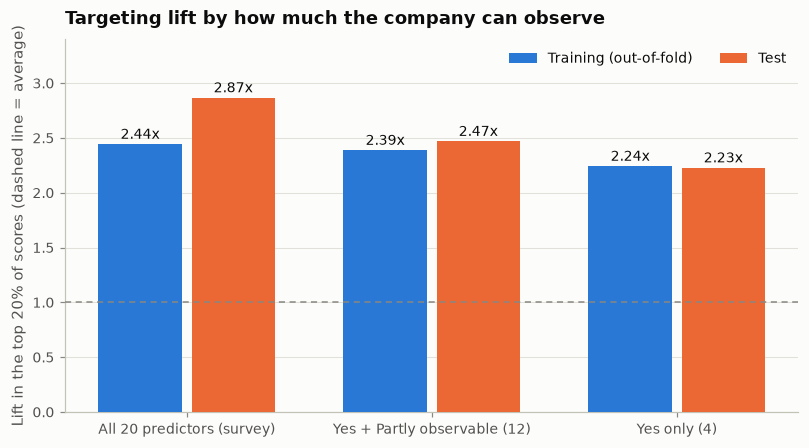

In [10]:
pivot = reachability.pivot(index="Predictors used", columns="File", values="Lift").loc[list(predictor_sets)]
x = np.arange(len(pivot))
fig, ax = plt.subplots(figsize=(8.6, 4.4))
for offset, (col, colour) in zip([-0.19, 0.19], [("Training (out-of-fold)", BLUE), ("Test", ORANGE)]):
    bars = ax.bar(x + offset, pivot[col], width=0.34, color=colour, label=col, zorder=3)
    for xi, v in zip(x + offset, pivot[col]):
        ax.text(xi, v + 0.05, f"{v:.2f}x", ha="center", fontsize=9, color=INK)
ax.axhline(1, color=MUTED, linewidth=1, linestyle=(0, (4, 3)), zorder=4)
ax.set_xticks(x, pivot.index)
ax.set_ylim(0, 3.4)
ax.set_ylabel("Lift in the top 20% of scores (dashed line = average)")
ax.set_title("Targeting lift by how much the company can observe")
ax.grid(axis="x", visible=False)
ax.legend(loc="upper right", ncol=2)
fig.savefig(FIG_DIR / "21_reachability_lift.png")
plt.show()

**Takeaways**

- **With everything a company could observe or partly observe (12 predictors),** the top 20% has a lift of 2.39 on training data, 98% of the full model's 2.44. On the test set it is 2.47 against 2.87, or 86%. It reaches 47.8% and 50.0% of users.
- **With only what a company clearly has (4 predictors: income, age, housing, debt-collection contact),** lift is 2.24 on training data and 2.23 on the test set, 92% and 78% of the full model. It reaches 44.9% and 42.0% of users.
- **How to read the gap between training and test.** The training figures rest on 448 users and are the steadier guide; the test set has 112, and the full model's 2.87 there was itself above its training value. A fair expectation for an observable-only campaign is a lift of about **2.2 to 2.5 times**, against about 2.4 to 2.9 with survey data.
- **The survey-only measures are not needed for reach.** Knowledge, savings, hardship, SNAP and shocks cannot be seen for a prospect, and dropping them costs between 2% and 22% of the lift depending on how much else the company knows.
- **The 12-predictor case is optimistic.** It assumes application or partner data (bank-account status, employment, credit rejections, payment history). For cold prospecting from marketing lists, the 4-predictor case is the realistic one.

---
# 5. Recommended marketing and origination strategy

The model supports a **needs-aware, transparent acquisition strategy**. It is a ranking tool for deciding where to make a clearly explained offer. It is not an approval rule and not a basis for pricing.

Each recommendation below states the evidence it rests on. Where a recommendation is a reasoned business proposal that the data cannot test, it says so.

In [11]:
t20 = test_segments.loc["Top 20% of model scores"]
tr20 = train_segments.loc["Top 20% of model scores"]
recall_test = t20["Users"] / int(y_test.sum())
recall_train = tr20["Users"] / int(y_train.sum())
opportunity = pd.DataFrame({
    "Training (out-of-fold)": [f"{len(y_train):,}", f"{int(y_train.sum())}", f"{int(tr20['People']):,} ({tr20['Share of file']:.1%})", f"{int(tr20['Users'])} ({recall_train:.1%})",
                               f"{tr20['Usage rate']:.1%}", f"{tr20['Lift']:.2f}x", f"{1 - tr20['Usage rate']:.1%}"],
    "Test": [f"{len(y_test):,}", f"{int(y_test.sum())}", f"{int(t20['People']):,} ({t20['Share of file']:.1%})", f"{int(t20['Users'])} ({recall_test:.1%})",
             f"{t20['Usage rate']:.1%}", f"{t20['Lift']:.2f}x", f"{1 - t20['Usage rate']:.1%}"],
}, index=["Respondents", "Prepaid users", "Flagged by the top-20% rule", "Users among those flagged (share of all users)",
          "Usage rate among those flagged", "Lift over the 8.8% average", "Flagged people who are not users"])
print("Size of the opportunity under the top-20% rule:")
display(opportunity)

flag = train_scores["score_chosen"] >= threshold
traits = {"At least one material hardship": train_raw["HARDSHIP_COUNT"] >= 1, "Savings under $1,000": train_raw["SAVINGSRANGES"] <= 3,
          "Household income under $30,000": train_raw["PPINCIMP"] <= 2, "No checking or savings account reported": train_raw["PRODHAVE_1"] == 0,
          "Contacted by a debt collector": train_raw["COLLECT"] == 1, "Household received SNAP benefits": train_raw["SNAP"] == 1}
fragility = pd.DataFrame({k: {"Flagged (top 20%)": v[flag].mean(), "Not flagged": v[~flag].mean(), "Everyone": v.mean()} for k, v in traits.items()}).T
print("Who the rule flags (training set): share of each group with the characteristic")
display(fmt(fragility, "{:.1%}"))

Size of the opportunity under the top-20% rule:


,Training (out-of-fold),Test
Respondents,"5,093","1,274"
Prepaid users,448,112
Flagged by the top-20% rule,"1,019 (20.0%)",246 (19.3%)
Users among those flagged (share of all users),219 (48.9%),62 (55.4%)
Usage rate among those flagged,21.5%,25.2%
Lift over the 8.8% average,2.44x,2.87x
Flagged people who are not users,78.5%,74.8%


Who the rule flags (training set): share of each group with the characteristic


,Flagged (top 20%),Not flagged,Everyone
At least one material hardship,71.1%,18.0%,28.6%
"Savings under $1,000",59.2%,14.9%,23.8%
"Household income under $30,000",58.0%,9.5%,19.2%
No checking or savings account reported,44.9%,6.3%,14.0%
Contacted by a debt collector,38.2%,7.1%,13.3%
Household received SNAP benefits,37.8%,2.6%,9.6%


| Decision | Recommendation | Evidence | Basis |
|---|---|---|---|
| **Who to target** | The top 20% of model scores. | Test set: 246 people flagged, 62 of 112 users reached (55.4%), usage rate 25.2%, lift 2.87. Training: 48.9% of users, lift 2.44 (Section 3). | Data |
| **How to find them** | Score prospects on observable data: bank-account status, housing, income, age, debt-collection contact, credit rejections. | Observable-only models keep a lift of 2.2 to 2.5 (Section 4). The largest weights are observable: bank account 0.58, debt collector 1.44, renting 1.62 (Section 2). | Data |
| **Second audience** | Run a separate, mainstream campaign for banked customers. Do not define the market as "the unbanked". | 69.2% of users have a bank account. The 229 users outside the top 20% are 89.1% banked (Section 3). | Data |
| **Channels** | Benefits and payroll partners, and community or credit-counselling referrals, alongside digital acquisition. | SNAP households use at 23.0% in training and 17.1% in test; disabled, unemployed and part-time workers at 16.0% and 15.0% (Section 3). The survey does not record how anyone was reached, so channel effectiveness is untested. | Reasoned proposal |
| **Message** | Lead with clear, predictable fees, direct deposit and budgeting control. No urgency or scarcity appeals. | The flagged group is financially fragile: 71.1% report a hardship, 59.2% have under \$1,000 saved, 58.0% have income under \$30,000 (table below). | Data on who; proposal on wording |
| **Origination** | Use the score to decide who gets an offer, never as an approval, pricing or fee rule. Offer a low-fee or fee-free path, and point to a basic bank account where that is cheaper. | 74.8% of flagged people in the test set are not users. Scores are rankings, not probabilities (Part 3). The outcome records use, not fees paid or ability to pay. | Data on limits; proposal on design |
| **Measurement** | Pilot before scaling. Track take-up, repeat use, fees paid, complaints and outcomes by group. | Results move between samples: SNAP lift 2.62 in training, 1.94 in test; Part 3's interval for the test ROC-AUC is 0.692 to 0.787. | Data |

---
# 6. Responsible marketing

Race/ethnicity is not a predictor and must not be used to select who receives an offer. That does not make the targeting rule race-neutral in its effect: income, housing, bank-account access and credit distress are unevenly distributed across groups, so a rule built on them reaches some groups far more than others. The table below shows who the top-20% rule reaches.

In [12]:
profile_train, profile_test = load_profile()
RACE = {1: "White, non-Hispanic", 2: "Black, non-Hispanic", 3: "Other, non-Hispanic", 4: "Hispanic"}


def reach_by_group(profile, y, scores):
    d = pd.DataFrame({"group": profile["PPETHM"].map(RACE), "flagged": scores["score_chosen"] >= threshold, "user": y})
    t = d.groupby("group").agg(People=("user", "size"), Share_flagged=("flagged", "mean"), Usage_rate=("user", "mean"))
    t["Usage rate among flagged"] = d[d["flagged"]].groupby("group")["user"].mean()
    return t.loc[list(RACE.values())]


reach = reach_by_group(profile_train, y_train, train_scores).add_suffix(" (train)").join(
    reach_by_group(profile_test, y_test, test_scores).add_suffix(" (test)"))
display(fmt(reach, {"People (train)": "{:,}", "Share_flagged (train)": "{:.1%}", "Usage_rate (train)": "{:.1%}", "Usage rate among flagged (train)": "{:.1%}",
                    "Share_flagged (test)": "{:.1%}", "Usage_rate (test)": "{:.1%}", "Usage rate among flagged (test)": "{:.1%}"}))

,People (train),Share_flagged (train),Usage_rate (train),Usage rate among flagged (train),People (test),Share_flagged (test),Usage_rate (test),Usage rate among flagged (test)
group,,,,,,,,
"White, non-Hispanic","3,586",12.9%,6.2%,17.9%,898,12.0%,4.9%,15.7%
"Black, non-Hispanic",536,43.8%,18.3%,27.7%,145,49.7%,20.0%,29.2%
"Other, non-Hispanic",270,18.5%,8.5%,8.0%,65,20.0%,9.2%,30.8%
Hispanic,701,38.5%,14.7%,24.8%,166,31.9%,19.9%,37.7%


**Takeaways**

- **The rule reaches Black and Hispanic respondents about three times as often as White respondents.** It flags 43.8% of Black and 38.5% of Hispanic respondents against 12.9% of White respondents in training (49.7%, 31.9% and 12.0% in the test set).
- **Part of that reflects real differences in use.** Usage rates are 18.3% (Black), 14.7% (Hispanic) and 6.2% (White) in training. The reach gap (3.4 times for Black against White respondents) is somewhat wider than the usage gap (3.0 times).
- **The rule is not flagging these groups on weaker evidence.** Among people flagged, 27.7% of Black and 24.8% of Hispanic respondents are users, against 17.9% of White respondents. The disparity comes from how income, housing, bank-account access and credit distress are distributed, not from the model treating groups differently.
- **The "Other, non-Hispanic" group is too small to read** (270 people in training, 65 in test; its flagged-usage rate swings from 8.0% to 30.8%).
- **What this means for the company.** A campaign built on this rule will fall disproportionately on Black and Hispanic households that are also financially fragile. Offer identical terms to everyone flagged, monitor offers, fees and complaints by group, and keep fees low. This is taken further in Part 5 (CFPB).

---
# 7. Conclusions and limitations for the card company

**Conclusions**

1. **A targeting strategy is supportable, as a ranking tool.** Scoring prospects and contacting the top 20% reaches about half of all prepaid users at 2.4 to 2.9 times the average usage rate.
2. **It works on observable data.** Bank-account status, housing, income, age and credit distress give a lift of 2.2 to 2.5 without any survey answers.
3. **There are two markets.** The model finds financially fragile users. Most users are banked and mainstream, and the model does not find them; they need a separate proposition.
4. **The commercial opportunity and the consumer-protection risk are the same people.** Those most likely to take the product are the least able to absorb fees, and they are disproportionately Black and Hispanic. Fee transparency and low-cost design are part of the strategy.

**Limitations**

- **Moderate accuracy.** Three in four people flagged are not users, and about half of users are missed.
- **Results vary between samples.** Segment rates differ between training and test, especially for small segments; the test set has only 112 users.
- **The observability labels are the team's judgement,** not a fact about any particular company's data.
- **The outcome is use, not value.** The survey does not record how often cards were used, what fees were paid, or whether the product suited the person, so nothing here measures profitability.
- **2016, self-reported, unweighted.** The figures describe this sample, are not national estimates, and may not reflect today's prepaid market.
- **Associations, not causes.** A high weight means two things go together, not that one produces the other.

### Hand-off

- **Task D (CFPB)** should take up the reach-by-group table in Section 6 and the overlap between the best prospects and the financially fragile.
- `score_chosen` in `data/train_oof_scores.csv` is the leakage-safe ranking for profiling; `data/test_scores.csv` is the confirmation set. The top-20% rule is `score_chosen >= 0.600`.
- Figures saved by this notebook: `figures/19_score_associations.png`, `figures/20_target_segments.png`, `figures/21_reachability_lift.png`.